# Generating new labels for unseen data to increase training set size

This notebook takes the ensemble of three models and runs it on unseen data to generate labels, the labels with very high (>0.95) and very low (<0.05) are kept as positives and negatives for the next round of training while the inbetweens wil be saved  to be checked manually by yours truly. Yeaah. 

In [ ]:
from opensoundscape import Audio, Spectrogram
from opensoundscape.annotations import BoxedAnnotations
import numpy as np
import pandas as pd
from glob import glob
from pathlib import Path

import matplotlib.pyplot as plt

from opensoundscape.ml.shallow_classifier import MLPClassifier, fit, fit_classifier_on_embeddings
import opensoundscape as opso
import bioacoustics_model_zoo as bmz

Load the model files

In [44]:
resnet = opso.load_model(r"model_training_checkpoints/best.model")
effnet = opso.load_model(r"Efficient_net/best.model")
perch = bmz.Perch2ONNX(headless=True)
import torch
torch.cuda.is_available()

/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/preprocess/overlay.py:126: UserWarning: Overlay class's .overlay_df will be None after loading from dict and `.criterion_fn` will be always_true(). Reset these attributes and set .bypass to False to use Overlay after loading with from_dict().
  warnings.warn(
/home/biofelip/anaconda3/envs/cv4animals/lib/python3.10/site-packages/opensoundscape/preprocess/overlay.py:126: UserWarning: Overlay class's .overlay_df will be None after loading from dict and `.criterion_fn` will be always_true(). Reset these attributes and set .bypass to False to use Overlay after loading with from_dict().
  warnings.warn(


True

Load the files to check, they will be a combination of the rest of the first airgun folder and some of the "background files"

In [47]:
airgun_folder=Path(r"/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Catalog AMARs/Airgun")
background_folder=Path(r"/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Catalog AMARs/Background noise")
# the files used during training or validation should not be included they can be found here
files_training = pd.read_csv(r"/mnt/j/HABITATWal/AMAR/HABITATWal.RDS/Sound Catalog AMARs/Already_trained_on_files.csv")

#glob the files for airguns
airgun_files = glob(str(airgun_folder.joinpath('*.wav')))
# erase the first two files that are the joined ones
airgun_files=airgun_files[2:]
# select the one that the model has not been trained on it should be 322
airgun_files = [x for x in  airgun_files if  Path(x).name not in set(files_training['file']) ]


# glob the files for the background
background_files=glob(str(background_folder.joinpath("*.wav")))
# subsample 10% of the background noises so i dont use all of them 
import random
import math
airgun_files_s = random.sample(airgun_files, math.floor(len(airgun_files)*0.25))
background_files_s =random.sample(background_files, math.floor(len(background_files)*0.1))

extract perch emdeddings  for both files, for the embedding we need to create a clips object so the embedding come out related to a file

In [48]:
clips_ag = opso.utils.make_clip_df(airgun_files_s+background_files_s, clip_duration=5)
perch_emb_ag=np.asanyarray(perch.embed(clips_ag, return_dfs=False, return_preds=False))
# perch_emb_bg=np.asanyarray(perch.embed(background_files_s, return_dfs=False, return_preds=False))

  0%|          | 0/344 [00:00<?, ?it/s]

load the shallow classifier and run the inference. 

In [49]:
import joblib
shallow = joblib.load("perch2onnx_headless_5s_logreg.joblib")
pred_perch=shallow.predict_proba(perch_emb_ag)[:,1]


(array([181., 175.,  98.,  68.,  49.,  27.,  31.,  29.,  47., 123.]),
 array([0.02385769, 0.12110211, 0.21834653, 0.31559094, 0.41283536,
        0.51007978, 0.6073242 , 0.70456862, 0.80181304, 0.89905745,
        0.99630187]),
 <BarContainer object of 10 artists>)

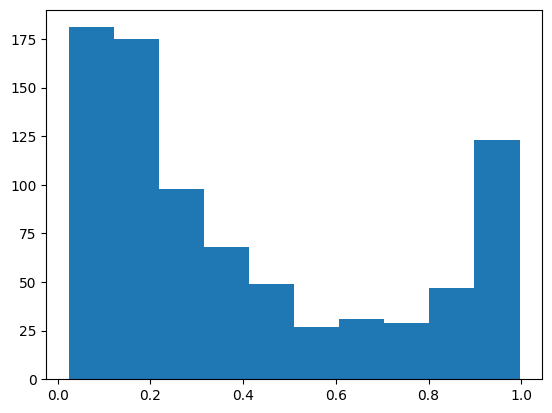

In [14]:
plt.hist(pred_perch)

Create the prediction for the other two models, the argument sigmoid creates true probabilities and the batch needs to be bigger than the default (1) to actually use the gpu. 

In [50]:
pred_resnet = resnet.predict(airgun_files_s + background_files_s, activation_layer="sigmoid",batch_size=32,num_workers=4)
pred_effnet = effnet.predict(airgun_files_s + background_files_s, activation_layer="sigmoid",batch_size=32,num_workers=4)

  0%|          | 0/11 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

(array([94., 39., 36., 34., 28., 19., 14., 17., 22., 41.]),
 array([0.12748501, 0.21456039, 0.3016358 , 0.38871118, 0.47578657,
        0.56286192, 0.64993739, 0.73701274, 0.8240881 , 0.91116357,
        0.99823892]),
 <BarContainer object of 10 artists>)

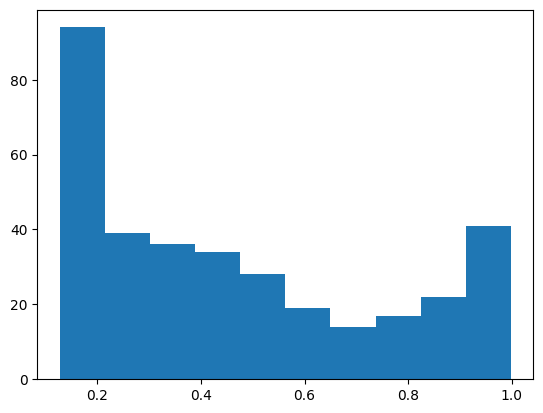

In [51]:
plt.hist(pred_resnet['airgun'])

(array([80., 79., 55., 39., 26.,  9.,  9.,  2., 13., 32.]),
 array([0.01620321, 0.11436857, 0.21253395, 0.31069931, 0.40886468,
        0.50703007, 0.60519546, 0.7033608 , 0.80152619, 0.89969158,
        0.99785691]),
 <BarContainer object of 10 artists>)

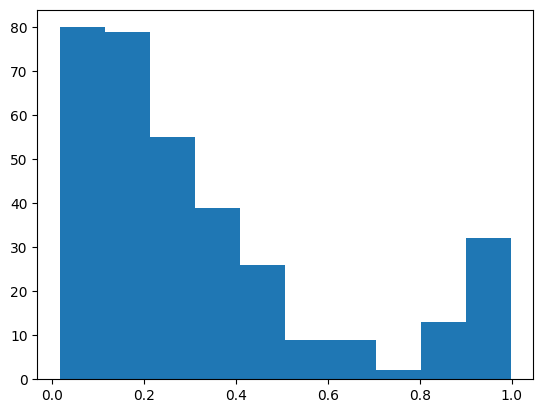

In [52]:
plt.hist(pred_effnet['airgun'])

Check for the files that are above and below the thresholds for the whole ensamble, here is important to remember that i have twice as many embeddings rows as i have files because most of the files are 10 second and the split was every 5 seconds. 

In [76]:
ens = pd.DataFrame({
    "resnet": pred_resnet["airgun"],
    "effnet": pred_effnet["airgun"],
}, index=clips_ag.index)            # works if you passed clips_ag to both predicts
ens["perch"] = pred_perch           # array, same order as clips_ag

assert not ens.isna().any().any()   # NaNs would mean the clip indexes don't line up

ens["mean"] = ens[["resnet", "effnet", "perch"]].mean(axis=1)
ens["spread"] = ens[["resnet", "effnet", "perch"]].max(axis=1) - ens[["resnet", "effnet", "perch"]].min(axis=1)

positives = ens[(ens["mean"] > 0.8) & (ens["spread"] < 0.40)]
negatives = ens[(ens["mean"] < 0.15) & (ens["spread"] < 0.4)]
review    = ens.drop(positives.index).drop(negatives.index)




print(len(positives), len(negatives), len(review))


42 52 250


We will check randomly 20% of the positives and the negatives to make sure that they are correct. If  more than five percent of the selected ones are not in the correct category move the threshold. 

In [79]:
from opensoundscape.visualization import annotate, inspect

positives_df = positives.reset_index()
widget= annotate(positives_df, N=math.floor(len(positives)*0.5), 
                 annotation_buttons=['airgun'],bandpass_range=(0,2000),
                 spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})

GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

In [84]:
n_checked = math.floor(len(positives) * 0.5)
n_wrong = (positives_df["airgun"] == 1).sum()      # clips you marked as airgun after all
print(f"of {n_checked} checked positives, {n_wrong} ({n_wrong / n_checked * 100:.1f}%) were correctly labelled as airgun")

of 21 checked positives, 21 (100.0%) were correctly labelled as airgun


In [86]:
negatives_df=negatives.reset_index()
widget= annotate(negatives_df, annotation_buttons=['airgun'], N=math.floor(len(negatives)*0.5), bandpass_range=(0,3000),
                 spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})


GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

In [88]:
n_checked = math.floor(len(negatives) * 0.5)
n_wrong = (negatives_df["airgun"] == 1).sum()      # clips you marked as airgun after all
print(f"of {n_checked} checked negatives, {n_wrong} ({n_wrong / n_checked * 100:.1f}%) were wrongly labelled as negative")

of 26 checked negatives, 0 (0.0%) were wrongly labelled as negative


The files that need to be reviwed can be annotated here direclty. 

In [90]:
review_df = review.reset_index()
print(f"you will have to review {len(review)} snippets, get ready!")

you will have to review 250 snippets, get ready!


In [108]:

batch = 4                      # increase by 1 for each new batch

idx = review_df.index[batch * 50 : (batch + 1) * 50]
annotate(review_df, indices=list(idx), 
         annotation_buttons=["airgun"], N=20,
         bandpass_range=(0, 1500),
         spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})
# review_df.to_csv("review_progress.csv", index=False)

GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

Print all the added airguns to the dataset

In [114]:
pos_idx = list(review_df.index[review_df["airgun"] == 1])
print(len(pos_idx))          # should be 31

widget = annotate(review_df, indices=pos_idx, N=len(pos_idx),
         bandpass_range=(0, 1500),
         spec_kwargs={"window_samples": 8200, "overlap_fraction": 0.75})

31


GridBox(children=(VBox(children=(HTML(value='<img src="data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAJsAAACaC…

In [119]:
print(f"from  a total of {len(review)} review files {(review_df['airgun'].eq(True)).sum()} are airguns and the rest are nothing (negatives)")

from  a total of 250 review files 31 are airguns and the rest are nothing (negatives)


In [169]:
labels = pred_resnet.copy()                 # a real copy
labels["airgun"] = 0                        # start: everything "no airgun"

# reviewed airguns: look them up by file + times, not by row number
rev_keys = review_df.loc[review_df["airgun"].eq(True), ["file", "start_time", "end_time"]]
labels.loc[pd.MultiIndex.from_frame(rev_keys), "airgun"] = 1

# auto-accepted positives (already indexed by file + times)
pos_keys = positives_df[["file", "start_time", "end_time"]]
labels.loc[pd.MultiIndex.from_frame(pos_keys), "airgun"] = 1

print(labels["airgun"].value_counts())      # 1s = review positives + auto positives



airgun
0    271
1     73
Name: count, dtype: int64


Save as a set of raven tables and as csv usable for future training. I dont have a lot of use for the annotations in rave right now because or raven lite but maybe they can be useful. 

In [177]:
from opensoundscape.annotations import BoxedAnnotations
sequence =1 
sequential_annotation_folder=f"annotations_step{sequence}" 
Path(sequential_annotation_folder).mkdir(exist_ok=True)
pos = labels[labels["airgun"] == 1].reset_index()
df = pd.DataFrame({
    "audio_file": pos["file"],
    "start_time": pos["start_time"],
    "end_time":   pos["end_time"],
    "annotation": "airgun",
    "low_f": 0,
    "high_f": 1000,
})
all_files = labels.index.get_level_values("file").unique().tolist()
boxes = BoxedAnnotations(df, audio_files=all_files)


boxes.to_csv(Path(sequential_annotation_folder).joinpath(f"ML_annotations_step{sequence}.csv"))       # OpenSoundscape's own format
boxes.to_raven_files(sequential_annotation_folder,
                     audio_files=boxes.df["audio_file"])         # Raven tables (the folder must exist)